In [1]:
import glob
import os

import autoroot
import matplotlib.pyplot as plt
import numpy as np
import torch

from src.data.lf.lf_datamodule import LF
from src.utils.tools import get_rho_lstsq

from pytorch_lightning import seed_everything

seed_everything(0, workers=True)

Seed set to 0


0

In [8]:
def data_illustration(inputs, outputs, rho=None, dim=0):

    fig, ax = plt.subplots(1, 2, figsize=(15, 5))

    ax[0].plot(inputs[0, :, dim].numpy())
    ax[0].plot(outputs[0, :, 0].numpy())

    if rho is not None:
        ax[1].plot(rho[dim])


seq_length = 1024


lf = LF(
    data_dir="",
    N=100,
    T=seq_length,
    D=1,
    rho_name="polynomial",
    rho_param={"alpha": 5},
    input_generator="randn",
    # inner_activation='tanh',
    # output_activation='tanh',
    # processing=["smooth_noise"]
)
data1 = lf.dataset_construction()[0]

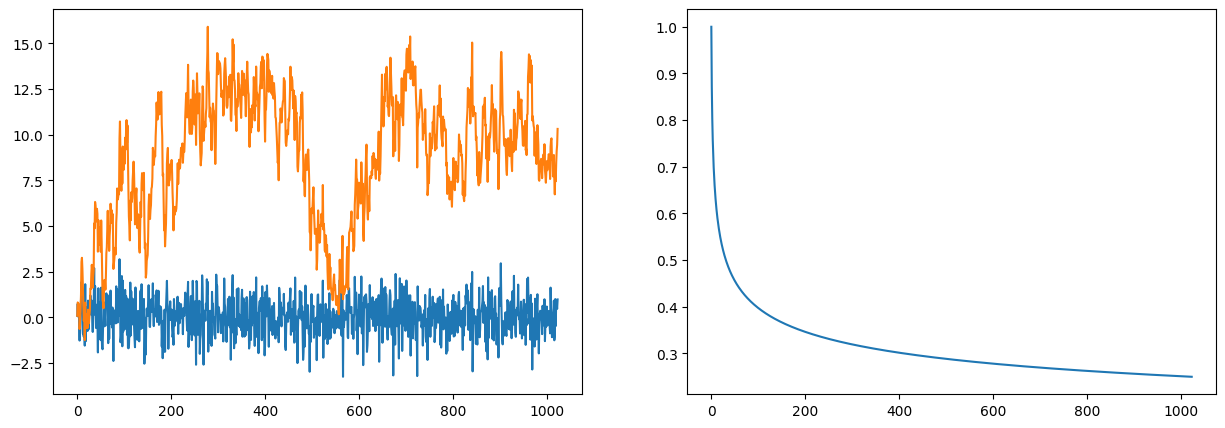

In [9]:
rho_vals = lf.rho_vals
data_illustration(data1[:][0], data1[:][1], rho_vals.numpy(), dim=0)


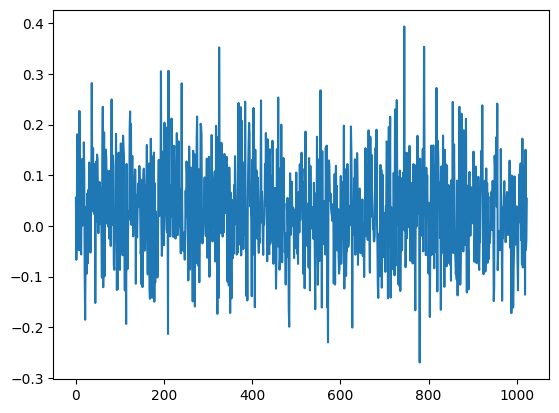

In [14]:
plt.plot(get_rho_lstsq(data1[:][0], data1[:][1], end_point=-1)[:,0])